# Л3 — Рішення з ціною помилки

Модель класифікації дає ймовірність події, наприклад відмови обладнання. Щоб із цього вийшло рішення — висилати бригаду чи ні, — модель має вчитися на чесних даних, а поріг має враховувати ціну кожної помилки.

Ноутбук нижче проходить цей шлях на одній задачі, спрощено. Більше туторіалів — у [Kaggle Learn](https://www.kaggle.com/learn), зокрема [Intro to Machine Learning](https://www.kaggle.com/learn/intro-to-machine-learning) та [Intermediate Machine Learning](https://www.kaggle.com/learn/intermediate-machine-learning) з уроками про витік даних, pipelines і крос-валідацію.

Типовий шлях задачі класифікації (у дужках — кроки цього ноутбука):

- зрозуміти дані (1);
- перевірити, чи дані чесні: витік, зміщена вибірка, data drift (2–4);
- підготувати ознаки: кодування категорій, масштабування (5). У реальних проєктах ці перетворення збирають у pipeline, щоб до нових даних застосовувались ті самі кроки; тут вони написані вручну;
- розділити дані на навчальну й валідаційну частини (5). Часто замість однієї валідаційної частини беруть крос-валідацію; тут її немає;
- порівняти кілька моделей (6);
- підібрати гіперпараметри (7). Зазвичай це перебір за сіткою з крос-валідацією (`GridSearchCV`); тут лише одна крива для `alpha`;
- обрати поріг рішення під задачу (8);
- застосувати модель до нових даних (9) і далі стежити, чи не погіршилась вона з часом.

І головне: гарна метрика на валідації ще не гарантує, що модель працюватиме на нових даних. Якщо в даних є витік, зміщення чи зсув, модель виглядатиме добре, а рішення будуть поганими.

Інші часті проблеми даних, про які варто пам'ятати:

- **незбалансовані класи** — подія рідкісна, і частка правильних відповідей оманлива. Тут відмов 5–9%, тому моделі порівнюють за PR-AUC (крок 6);
- **замало даних** — модель запам'ятовує навчальні приклади замість закономірності; близьке явище видно на кривій перенавчання (крок 7);
- **пропуски й помилки в даних** — Л1;
- **помилки в мітках** — частину об'єктів позначено неправильно, і модель вчиться на цих помилках; тут цього немає;
- **зв'язок без причини** — ознака пов'язана з ціллю через третій чинник, а не напряму; Л2.

Шаблон веде покроково: у кожному кроці — навіщо він і що зробити, у клітинці з `TODO` — ваш код. Опис даних, вартості й таблиця пасток — у `README.md`.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from pathlib import Path

## 1. Завантаження даних

Спершу подивіться, що всередині файлів: розмірність, колонки, типи й частку відмов у `train`. Можуть допомогти `df.head()`, `df.shape` і `df.dtypes`.

Вартості свого варіанта впишіть із таблиці в `README.md`: від них залежить правило рішення в кроці 8.

In [23]:
COST_VISIT = 1800
COST_FAILURE = 60000

# TODO: завантажте registry.csv, train.csv і test.csv свого варіанта з папки variants/<варіант>/ і виведіть частку failed у train
# Шлях до папки з файлами
DATA_DIR = Path.cwd()
print("Робоча папка:", DATA_DIR.resolve())

# Завантаження даних
registry = pd.read_csv(DATA_DIR / "registry.csv")
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

print("Registry:", registry.shape)
print("Train:", train.shape)
print("Test:", test.shape)

print("\nПерші 5 рядків train:")
display(train.head())

print("\nТипи даних train:")
print(train.dtypes)

print("\nЧастка відмов:", round(train["failed"].mean(), 4))
print("Кількість відмов:", int(train["failed"].sum()))
print("Поріг рішення:", COST_VISIT / COST_FAILURE)

Робоча папка: E:\.ARTUR\.Study\C5_Pr.1\ІАДдЗЕ\L3
Registry: (6000, 8)
Train: (4023, 20)
Test: (1977, 19)

Перші 5 рядків train:


,object_id,load_mean,load_std,load_stability,load_weekend_ratio,temp_rise_mean,temp_rise_std,temp_rise_median,pd_mean,pd_std,pd_stability,pd_per_load,temp_per_load,equipment_type,voltage_class,region,install_year,last_overhaul_year,outdoor,failed
0,EQ100001,80.747,11.030,0.8798,0.8166,14.116,1.011,14.090,35.372,7.502,0.8250,0.4381,0.1748,switchgear,kv6,north,2015,2019,0,0
1,EQ100006,73.220,9.341,0.8869,0.7827,34.596,2.914,35.380,66.827,13.234,0.8347,0.9127,0.4725,switchgear,kv10,west,2016,2018,0,0
2,EQ100007,40.589,6.435,0.8632,0.8179,15.880,1.122,16.065,92.820,15.291,0.8586,2.2868,0.3912,switchgear,kv35,south,2019,2023,0,0
3,EQ100008,23.336,3.888,0.8572,0.7729,10.512,0.611,10.580,36.609,8.019,0.8203,1.5688,0.4505,meter_unit,kv35,west,2020,2020,0,0
4,EQ100009,72.511,10.793,0.8704,0.8024,18.943,1.642,19.370,33.031,7.733,0.8103,0.4555,0.2612,switchgear,kv6,centre,1979,2018,0,0



Типи даних train:
object_id                 str
load_mean             float64
load_std              float64
load_stability        float64
load_weekend_ratio    float64
temp_rise_mean        float64
temp_rise_std         float64
temp_rise_median      float64
pd_mean               float64
pd_std                float64
pd_stability          float64
pd_per_load           float64
temp_per_load         float64
equipment_type            str
voltage_class             str
region                    str
install_year            int64
last_overhaul_year      int64
outdoor                 int64
failed                  int64
dtype: object

Частка відмов: 0.0557
Кількість відмов: 224
Поріг рішення: 0.03


## 2. Витік (M-1)

Витік (data leakage) — колонка, значення якої стає відомим лише після того, що ми хочемо передбачити. Наприклад, у даних про відмови може бути колонка «вартість ремонту». Вона дуже точно «передбачає» відмову: ремонтують саме те, що зламалося. Але вартість ремонту з'являється вже після відмови, а рішення ухвалюють раніше, коли об'єкт ще працює й цього значення немає. Модель, навчена на такій колонці, на навчальних даних виглядає чудово, а на нових об'єктах не працює. Такі колонки прибирають.

Не завжди відомо, коли заповнюють кожну колонку, тож витік шукають за ознакою «надто добре вгадує». Для кожної колонки окремо рахують **ROC AUC** — ймовірність того, що у випадкового об'єкта, який відмовив, значення колонки більше, ніж у випадкового справного. 0.5 — колонка не відрізняє їх зовсім, як підкидання монети; 1 — відрізняє ідеально. Звичайна ознака на кшталт температури чи навантаження так точно не вгадує. Колонку з AUC понад 0.9 тут вважають витоком. У реальному проєкті висока AUC — привід з'ясувати, коли колонку заповнюють.

1. Для кожної числової колонки `train`, крім `failed`, порахуйте `roc_auc_score(train["failed"], колонка)`. Якщо AUC менше 0.5, візьміть 1 − AUC: колонка пов'язана з відмовою навпаки, у тих, що відмовили, значення менші.
2. Виведіть AUC усіх колонок від більшого до меншого.
3. Колонки з AUC більше 0.9 приберіть із `train` і `test`.

Можуть допомогти `select_dtypes("number")`, `sort_values` і `drop(columns=...)`.

In [ ]:
# TODO: M-1
numeric_cols = train.select_dtypes(include="number").columns.drop(
    "failed", errors="ignore"
)

auc_values = {}

# Розрахунок ROC AUC
for col in numeric_cols:
    auc = roc_auc_score(train["failed"], train[col])

    auc_values[col] = max(auc, 1 - auc)

# Сортування ознак за ROC AUC
auc_table = pd.Series(
    auc_values, name="ROC_AUC"
).sort_values(ascending=False).to_frame()

print("ROC AUC числових ознак:")
display(auc_table)

# Ознаки з AUC понад 0.9 - потенційний витік 
leak_columns = auc_table.index[
    auc_table["ROC_AUC"] > 0.9
].tolist()

print("\nОзнака з найбільшим ROC AUC:", auc_table.index[0])
print("Найбільший ROC AUC:", round(auc_table.iloc[0, 0], 4))
print("\nКолонки з ROC AUC > 0.9:", leak_columns)

# Виділення знайдених колонкок з train і test
if leak_columns:
    train.drop(columns=leak_columns, inplace=True)
    test.drop(
        columns=[c for c in leak_columns if c in test.columns],
        inplace=True
    )
    print("Видалено потенційний витік:", leak_columns)
else:
    print("Колонок із ROC AUC > 0.9 не знайдено.")

print("\nНовий розмір train:", train.shape)
print("Новий розмір test:", test.shape)


ROC AUC числових ознак:


,ROC_AUC
temp_rise_std,0.824105
temp_rise_median,0.821498
temp_rise_mean,0.821159
pd_mean,0.751406
pd_std,0.746780
load_mean,0.669405
load_std,0.669102
temp_per_load,0.667542
pd_per_load,0.607424
install_year,0.559545



Ознака з найбільшим ROC AUC: temp_rise_std
Найбільший ROC AUC: 0.8241

Колонки з ROC AUC > 0.9: []
Колонок із ROC AUC > 0.9 не знайдено.

Новий розмір train: (4023, 20)
Новий розмір test: (1977, 19)


## 3. Зміщена вибірка (M-2)

Завжди треба враховувати, як збирали дані. Наприклад, лікарня має дані переважно про людей, які прийшли з підозрою на хворобу: здорові приходять туди набагато рідше. Тож хворих у таких даних набагато більше, ніж серед усіх людей. Таке зміщення вибірки (selection bias) буває й в інших задачах: результат відомий не для всіх об'єктів, а переважно для тих, що вже викликали підозру.

Модель на таких даних усе ще може навчитися відрізняти ризикові об'єкти від решти. Але числа, пораховані на зміщеній вибірці, — частку подій, точність, ефект рішення — не можна переносити на всі об'єкти: вони будуть спотворені.

У цій задачі `registry.csv` містить усі об'єкти, а `train.csv` — лише ті об'єкти `history`, для яких відомо, чи вони відмовили.

Поділіть кількість рядків `train` на кількість об'єктів `registry` з `cohort == "history"` і виведіть частку; менше 0.9 — вибірка зміщена. Тоді виведіть ще середній `install_year` об'єктів `history`, що є в `train`, і об'єктів `history`, яких у `train` немає. Може допомогти `isin`.

У коді після цього нічого не змінюється: рішення будується так само, але частку відмов і ефект на валідації не можна переносити на всі об'єкти.

In [16]:
# TODO: M-2
# Усі об'єкти, для яких період спостереження завершений
history_registry = registry[
    registry["cohort"] == "history"
].copy()

# Об'єкти history, що є в train
train_ids = train["object_id"].unique()

history_in_train = history_registry[
    history_registry["object_id"].isin(train_ids)
]

# Об'єкти history, яких немає в train
history_not_train = history_registry[
    ~history_registry["object_id"].isin(train_ids)
]

# Частка об'єктів history, для яких є результати
train_fraction = len(train) / len(history_registry)

print("Усього об'єктів history:", len(history_registry))
print("Рядків у train:", len(train))
print("History, присутні в train:", len(history_in_train))
print("History, відсутні в train:", len(history_not_train))

print("\nЧастка train / history:", round(train_fraction, 4))
print("Поріг перевірки: 0.9")

if train_fraction < 0.9:
    print("Висновок: M-2 ВИЯВЛЕНО")
else:
    print("Висновок: M-2 НЕ ВИЯВЛЕНО")

print(
    "\nСередній install_year для history у train:",
    round(history_in_train["install_year"].mean(), 2)
)

print(
    "Середній install_year для history поза train:",
    round(history_not_train["install_year"].mean(), 2)
)

Усього об'єктів history: 4023
Рядків у train: 4023
History, присутні в train: 4023
History, відсутні в train: 0

Частка train / history: 1.0
Поріг перевірки: 0.9
Висновок: M-2 НЕ ВИЯВЛЕНО

Середній install_year для history у train: 1999.14
Середній install_year для history поза train: nan


## 4. Зсув у часі (M-3)

Властивості об'єктів змінюються з часом: люди старішають, обладнання зношується, датчик після калібрування чи заміни починає показувати інакше. Тому дані різних періодів можуть відрізнятися. Це називають **data drift** (зсув даних). Коли ж змінюється сам зв'язок ознак із ціллю, це **concept drift**; тут його немає.

Проблема виникає, коли зсув не врахували. Модель вивчила, що звичайна температура — 40 °C, а в нових даних датчик показує 45 °C для таких самих об'єктів. Модель побачить «гарячіші» об'єкти й помилятиметься, хоча нічого не змінилося.

**Як помітити:** порівняти розподіл ознак у навчальних і нових даних — середні, гістограми. Тут зсув середнього міряють у стандартних відхиленнях train: 0.5 — половина звичайного розкиду між об'єктами. Зсув рахують зі знаком: від'ємний означає, що в нових даних значення нижчі.

**Як боротися** — залежить від причини:

- **змінилася шкала вимірювання** (калібрування, інший датчик), а об'єкти ті самі — ознаки зводять до однієї шкали, наприклад стандартизують окремо в кожному періоді. Середнє стає 0, відхилення 1, а порядок об'єктів — хто гарячіший за кого — лишається;
- **змінилися самі об'єкти** — таке вирівнювання стерло б справжні зміни. Тоді модель перенавчають на свіжих даних і регулярно перевіряють її якість.

У цій задачі `train.csv` описує перший період, `test.csv` — другий. Якщо зсув є, він — у шкалі температурного датчика, тож підходить перший спосіб.

1. Виведіть зсув зі знаком: (середнє `temp_rise_mean` у test − середнє в train) / стандартне відхилення `temp_rise_mean` у train. Відхилення — `.std()` з pandas.
2. Якщо зсув більший за 0.5, стандартизуйте колонки `temp`: у train — середнім і відхиленням train, у test — середнім і відхиленням test. Якщо стандартизувати test за train, зсув лишиться.

In [17]:
temp = ["temp_rise_mean", "temp_rise_std", "temp_rise_median", "temp_per_load"]

# TODO: M-3 — зсув і, якщо він більший за 0.5, стандартизація temp окремо в train і в test
# Розрахунок зсуву до стандартизації
temp_shift = (
    test["temp_rise_mean"].mean()
    - train["temp_rise_mean"].mean()
) / train["temp_rise_mean"].std()

print("Середнє temp_rise_mean у train:",
      round(train["temp_rise_mean"].mean(), 4))

print("Середнє temp_rise_mean у test:",
      round(test["temp_rise_mean"].mean(), 4))

print("Стандартне відхилення у train:",
      round(train["temp_rise_mean"].std(), 4))

print("Зсув M-3:", round(temp_shift, 4))
print("Поріг перевірки: 0.5")

# Якщо зсув більший за 0.5 - стандартизація temp окремо в train і в test
if temp_shift > 0.5:
    train[temp] = (
        train[temp] - train[temp].mean()
    ) / train[temp].std()

    test[temp] = (
        test[temp] - test[temp].mean()
    ) / test[temp].std()

    print("\nВисновок: M-3 ВИЯВЛЕНО.")
    print("Температурні ознаки стандартизовано окремо.")
else:
    print("\nВисновок: M-3 НЕ ВИЯВЛЕНО.")
    print("Стандартизація через M-3 не потрібна.")

Середнє temp_rise_mean у train: 15.7649
Середнє temp_rise_mean у test: 21.0558
Стандартне відхилення у train: 5.7463
Зсув M-3: 0.9207
Поріг перевірки: 0.5

Висновок: M-3 ВИЯВЛЕНО.
Температурні ознаки стандартизовано окремо.


## 5. Ознаки й поділ

Моделі працюють із числами, тому категорійні колонки кодують **one-hot**: окрема колонка 0/1 на кожне значення. Порядкових номерів категоріям не дають, бо `north` не «більше» за `south`.

**Валідаційна частина.** Щоб зрозуміти, як модель працюватиме на нових об'єктах, її перевіряють на даних, яких вона не бачила під час навчання. Для цього частину `train` відкладають убік — це валідаційна частина. На ній і порівнюють моделі: модель, що просто запам'ятала навчальні об'єкти, на навчальних даних виглядатиме ідеально, а на валідаційних — ні.

Валідаційна частина має бути схожою на дані, до яких модель застосовуватимуть. Відмови рідкісні, тож при випадковому поділі частка відмов у ній може помітно відрізнятися від навчальної, а в малому наборі даних відмов там може не виявитися зовсім, і оцінити модель стане неможливо. `stratify=y` зберігає однакову частку відмов в обох частинах.

**Масштабування.** Ознаки мають різні одиниці й розміри: `load_mean` — від 15 до 148 А, а `load_stability` — від 0.85 до 0.91. Метод опорних векторів, найближчі сусіди й перцептрон рахують відстані чи зважені суми, тож для них різниця навантаження в 100 переважить різницю стабільності в 0.05, навіть якщо стабільність важливіша. Тому ознаки стандартизують: середнє 0, стандартне відхилення 1. Дереву рішень і наївному Баєсу масштаб не заважає. Середні й відхилення беруть лише з навчальної частини: якщо взяти їх з усіх даних, валідаційна частина вплине на навчання — це теж витік, як у кроці 2.

1. Зберіть ознаки через `pd.get_dummies(..., columns=categorical, dtype=float)`: `X` — з `train` без `object_id` і `failed`, `X_test` — з `test` без `object_id`. Колонки `X_test` мають іти в тому самому порядку, що в `X`: `X_test[X.columns]`.
2. `y` — колонка `failed`.
3. Поділ і стандартизацію задано нижче: `StandardScaler` навчається лише на `X_tr` і тим самим перетворенням застосовується до `X_va` і `X_test`.

In [18]:
categorical = ["equipment_type", "voltage_class", "region"]

# TODO: X, X_test і y
# Формування ознаки для навчання
X = train.drop(columns=["object_id", "failed"]).copy()

# Формування ознаки для тестових об'єктів
X_test = test.drop(columns=["object_id"]).copy()

# Кодування категорій методом One-Hot Encoding
X = pd.get_dummies(
    X,
    columns=categorical,
    dtype=float
)

X_test = pd.get_dummies(
    X_test,
    columns=categorical,
    dtype=float
)

# Узгодженняя порядку і набору колонок
X_test = X_test.reindex(columns=X.columns, fill_value=0)

# Цільова змінна: 1 — відмова, 0 — відсутність відмови
y = train["failed"].astype(int)

print("Розмір X:", X.shape)
print("Розмір X_test:", X_test.shape)
print("Розмір y:", y.shape)

print("\nЧастка відмов:", round(y.mean(), 4))
print("Кількість ознак:", X.shape[1])
print("Кількість колонок збігається:",
      list(X.columns) == list(X_test.columns))

X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)

scaler = StandardScaler().fit(X_tr)
X_tr, X_va, X_te = scaler.transform(X_tr), scaler.transform(X_va), scaler.transform(X_test)

print("\nРозмір навчальної частини:", X_tr.shape)
print("Розмір валідаційної частини:", X_va.shape)
print("Розмір тестової частини:", X_te.shape)

Розмір X: (4023, 25)
Розмір X_test: (1977, 25)
Розмір y: (4023,)

Частка відмов: 0.0557
Кількість ознак: 25
Кількість колонок збігається: True

Розмір навчальної частини: (3017, 25)
Розмір валідаційної частини: (1006, 25)
Розмір тестової частини: (1977, 25)


## 6. П'ять моделей

**Як порівнювати.** Звична метрика — **accuracy**, частка правильних відповідей. При рідкісних подіях вона оманлива: якщо відмов 8%, модель, яка завжди каже «не відмовить», має accuracy 92%, але не знаходить жодної відмови.

Тому тут порівнюють інакше. Модель упорядковує об'єкти від найризикованішого до найспокійнішого. Якщо брати об'єкти згори списку, можна рахувати **precision** — яка частка взятих справді відмовила, і **recall** — яку частку всіх відмов уже знайдено. **PR-AUC** (`average_precision_score`) — середня precision, поки список росте від першої знайденої відмови до останньої. 1 — усі відмови стоять на самому верху списку; якщо порядок випадковий, PR-AUC дорівнює частці відмов. Тому PR-AUC завжди порівнюють із часткою відмов.

| Модель | Як оцінює ймовірність відмови |
|---|---|
| дерево рішень | ділить об'єкти порогами ознак; ймовірність — частка відмов у листку. `max_depth` обмежує кількість поділів |
| метод опорних векторів | шукає межу з найширшим проміжком між класами; сам дає лише відстань до межі, а `CalibratedClassifierCV` перетворює її на ймовірність |
| найближчі сусіди | частка відмов серед `n_neighbors` найближчих об'єктів навчальної частини |
| наївний Баєс | формула Баєса за припущення, що ознаки незалежні |
| багатошаровий перцептрон | прихований шар із 32 нейронів: кожен зважує ознаки й пропускає суму через функцію активації ReLU; вихідний нейрон дає ймовірність. Ваги підбирає зворотне поширення помилки, `alpha` — штраф за великі ваги |

Якщо навчальна PR-AUC набагато вища за валідаційну, модель запам'ятала навчальні об'єкти, а не навчилася розпізнавати ризик. Це **перенавчання** (overfitting), про нього — крок 7.

Далі рішення ухвалює перцептрон: на ньому в кроці 7 показано перенавчання, і рецепт однаковий для всіх варіантів. На ваших даних інша модель може бути кращою — це нормально, у звіті просто назвіть її. У реальному проєкті для рішення взяли б найкращу модель на валідації.

1. Навчіть кожну модель зі словника `models` на `X_tr`, `y_tr` і виведіть таблицю: модель, PR-AUC на навчальній і на валідаційній частині. PR-AUC рахуйте за ймовірностями `predict_proba(...)[:, 1]`. Функція, що рахує PR-AUC моделі на обох частинах, знадобиться ще в кроці 7.
2. Виведіть частку відмов у `y_va`.
3. Знайдіть найкращу модель на валідаційній частині й порівняйте її PR-AUC і PR-AUC перцептрона з часткою відмов — це відповідь для питання 2 звіту.

In [19]:
models = {
    "дерево рішень": DecisionTreeClassifier(max_depth=5, random_state=0),
    "опорні вектори": CalibratedClassifierCV(SVC(), ensemble=False),
    "найближчі сусіди": KNeighborsClassifier(n_neighbors=25),
    "наївний Баєс": GaussianNB(),
    "перцептрон": MLPClassifier(hidden_layer_sizes=(32,), alpha=1.0, max_iter=1000, random_state=0),
}

# TODO: навчіть моделі й виведіть таблицю PR-AUC і частку відмов у y_va
# Функція навчання моделі та обчислення PR-AUC
def evaluate_pr_auc(model, X_train, y_train, X_eval, y_eval):
    model.fit(X_train, y_train)

    train_prob = model.predict_proba(X_train)[:, 1]
    eval_prob = model.predict_proba(X_eval)[:, 1]

    train_pr_auc = average_precision_score(
        y_train, train_prob
    )
    eval_pr_auc = average_precision_score(
        y_eval, eval_prob
    )

    return train_pr_auc, eval_pr_auc


# Навчання всіх п'яти моделей
results = []

for name, model in models.items():
    train_score, val_score = evaluate_pr_auc(
        model, X_tr, y_tr, X_va, y_va
    )

    results.append({
        "Модель": name,
        "PR-AUC train": train_score,
        "PR-AUC validation": val_score
    })

# Таблиця результатів
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    "PR-AUC validation",
    ascending=False
).reset_index(drop=True)

print("Порівняння моделей:")
display(results_df.round(4))

# Частка відмов у валідаційній частині
failure_rate_val = y_va.mean()

print(
    "\nЧастка відмов у валідаційній частині:",
    round(failure_rate_val, 4)
)

# Найкраща модель за валідаційною PR-AUC
best_model_name = results_df.iloc[0]["Модель"]
best_model_score = results_df.iloc[0]["PR-AUC validation"]

print("\nНайкраща модель:", best_model_name)
print("Її валідаційна PR-AUC:", round(best_model_score, 4))

# Окремий показ результату перцептрона
perceptron_result = results_df[
    results_df["Модель"] == "перцептрон"
].iloc[0]

print(
    "\nPR-AUC перцептрона на train:",
    round(perceptron_result["PR-AUC train"], 4)
)
print(
    "PR-AUC перцептрона на validation:",
    round(perceptron_result["PR-AUC validation"], 4)
)

Порівняння моделей:


,Модель,PR-AUC train,PR-AUC validation
0,перцептрон,0.4359,0.2889
1,наївний Баєс,0.3234,0.2735
2,опорні вектори,0.7999,0.2698
3,найближчі сусіди,0.3514,0.2561
4,дерево рішень,0.4994,0.1411



Частка відмов у валідаційній частині: 0.0557

Найкраща модель: перцептрон
Її валідаційна PR-AUC: 0.2889

PR-AUC перцептрона на train: 0.4359
PR-AUC перцептрона на validation: 0.2889


## 7. Перенавчання перцептрона

**Перенавчання** — модель запам'ятовує навчальні приклади разом із їхнім шумом, замість того щоб знайти загальну закономірність. Як студент, що завчив відповіді до конкретних білетів: на цих білетах — відмінно, на нових — погано. Ознака перенавчання: навчальна метрика висока, валідаційна — значно нижча.

Один зі способів боротьби — **регуляризація**: штраф, що змушує модель бути простішою. У перцептрона це `alpha` — штраф за великі ваги. Із малим `alpha` мережа підлаштовує ваги під кожен навчальний об'єкт, і її ймовірності стають надто впевненими, близькими до 0 або 1. Правилу з кроку 8 потрібні правдоподібні ймовірності, тому для рішення взято `alpha=1`. У реальному проєкті `alpha` підбирали б перебором (див. вступ).

Якщо при малих `alpha` з'явиться попередження `ConvergenceWarning`, воно означає, що оптимізатор не встиг зійтися за `max_iter` ітерацій: мережа все ще підганяється під навчальні об'єкти.

1. Для кожного `alpha` зі списку навчіть такий самий перцептрон, як у кроці 6, але з цим `alpha`. Перцептрон із кроку 6 не перезаписуйте: він потрібен у кроках 8–9.
2. Виведіть таблицю «alpha, PR-AUC на навчальній і на валідаційній частині» і побудуйте обидві криві на одному графіку; вісь `alpha` — логарифмічна (`plt.xscale("log")`).
3. Прочитайте криву: що відбувається з навчальною і валідаційною PR-AUC, коли `alpha` зменшується, і при якому `alpha` розрив найбільший — це відповідь для питання 2 звіту.

Результати для різних alpha:


,alpha,PR-AUC train,PR-AUC validation
0,0.0001,0.8504,0.2316
1,0.0010,0.8639,0.1972
2,0.0100,0.6399,0.2517
3,0.1000,0.6261,0.2591
4,1.0000,0.4359,0.2889



Найбільший розрив PR-AUC:
alpha: 0.001
Розрив: 0.6668


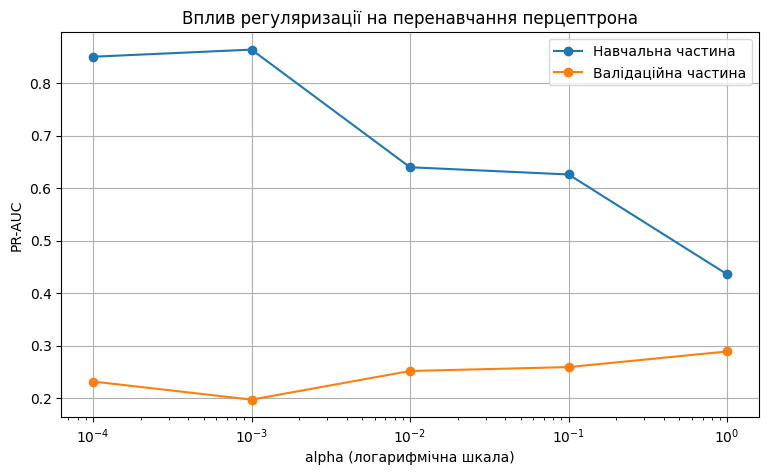

In [20]:
alphas = [0.0001, 0.001, 0.01, 0.1, 1.0]

# TODO: таблиця й графік PR-AUC від alpha
curve_results = []

for alpha in alphas:
    model = MLPClassifier(
        hidden_layer_sizes=(32,),
        alpha=alpha,
        max_iter=1000,
        random_state=0
    )

    train_score, val_score = evaluate_pr_auc(
        model, X_tr, y_tr, X_va, y_va
    )

    curve_results.append({
        "alpha": alpha,
        "PR-AUC train": train_score,
        "PR-AUC validation": val_score
    })

curve_df = pd.DataFrame(curve_results)

print("Результати для різних alpha:")
display(curve_df.round(4))

# Визначення найбільшого розриву між навчальною та валідаційною PR-AUC
curve_df["Розрив"] = (
    curve_df["PR-AUC train"]
    - curve_df["PR-AUC validation"]
)

max_gap_row = curve_df.loc[curve_df["Розрив"].idxmax()]

print("\nНайбільший розрив PR-AUC:")
print("alpha:", max_gap_row["alpha"])
print("Розрив:", round(max_gap_row["Розрив"], 4))

# Побудова кривої
plt.figure(figsize=(9, 5))

plt.plot(
    curve_df["alpha"],
    curve_df["PR-AUC train"],
    marker="o",
    label="Навчальна частина"
)

plt.plot(
    curve_df["alpha"],
    curve_df["PR-AUC validation"],
    marker="o",
    label="Валідаційна частина"
)

plt.xscale("log")
plt.xlabel("alpha (логарифмічна шкала)")
plt.ylabel("PR-AUC")
plt.title("Вплив регуляризації на перенавчання перцептрона")
plt.legend()
plt.grid(True)
plt.show()

## 8. Правило рішення

Модель дає ймовірність, а диспетчер має вирішити «їхати чи ні». Звичний поріг 0.5 означає «їхати, якщо відмова ймовірніша, ніж її відсутність». Але помилки коштують по-різному: зайвий виїзд — `COST_VISIT`, пропущена відмова — `COST_FAILURE`, у десятки разів дорожче. Тож виїзд виправданий і за значно меншої ймовірності.

Не поїхати до об'єкта з ймовірністю відмови p — у середньому втратити p · `COST_FAILURE`. Виїзд окупається, коли p · `COST_FAILURE` не менше за `COST_VISIT`, тобто коли p не менша за поріг `COST_VISIT / COST_FAILURE`.

Правило працює, лише якщо ймовірностям можна вірити: серед об'єктів з ймовірністю 0.1 має справді відмовляти близько 10%. Це називають **калібруванням** (calibration). Перша проста перевірка — середня ймовірність має бути близькою до частки відмов.

Ефект рішення — скільки гривень воно зберігає проти «нікого не перевіряти»:

- витрати «нікого не перевіряти» = кількість відмов · `COST_FAILURE`;
- витрати рішення = кількість виїздів · `COST_VISIT` + кількість об'єктів, що відмовили і до яких не виїхали, · `COST_FAILURE`;
- ефект = перше − друге.

1. Порахуйте поріг `COST_VISIT / COST_FAILURE` і ймовірності перцептрона з кроку 6 на `X_va`.
2. Виведіть поріг, середню ймовірність і частку відмов у `y_va`.
3. Виведіть таблицю для трьох правил — поріг з вартостей, поріг 0.5, перевірити всіх: скільки об'єктів на виїзд і ефект у гривнях. Ефект для трьох правил — одна функція від рішень, а не три копії формули. `y_va` після поділу має перемішаний індекс, тож рішення порівнюйте з `y_va.to_numpy()`.
4. Порівняйте три правила: яке зберігає найбільше і чому поріг 0.5 тут поганий — це відповідь для питання 3 звіту.

In [21]:
# TODO: поріг, ймовірності й таблиця трьох правил
# Поріг, за якого очікувана вартість пропущеної відмови стає не меншою за вартість виїзду
threshold_cost = COST_VISIT / COST_FAILURE

# Прогнозовані ймовірності для валідаційної частини
perceptron = models["перцептрон"]
p_va = perceptron.predict_proba(X_va)[:, 1]

# Справжні мітки валідаційної частини
y_true = y_va.to_numpy()

print("Поріг за вартостями:", round(threshold_cost, 4))
print("Середня прогнозована ймовірність:", round(p_va.mean(), 4))
print("Частка відмов у валідаційній частині:", round(y_true.mean(), 4))

# Базові витрати, якщо не перевіряти жодного об'єкта
baseline_cost = y_true.sum() * COST_FAILURE


# Функція оцінювання рішення
def evaluate_decision(name, decision):
    decision = np.asarray(decision, dtype=int)

    visits = int(decision.sum())

    missed_failures = int(
        ((y_true == 1) & (decision == 0)).sum()
    )

    total_cost = (
        visits * COST_VISIT
        + missed_failures * COST_FAILURE
    )

    effect = baseline_cost - total_cost

    return {
        "Правило": name,
        "Кількість виїздів": visits,
        "Ефект, грн": int(effect)
    }


# Три правила для порівняння
rules = [
    evaluate_decision(
        f"Поріг за вартостями = {threshold_cost:.2f}",
        p_va >= threshold_cost
    ),
    evaluate_decision(
        "Поріг 0.5",
        p_va >= 0.5
    ),
    evaluate_decision(
        "Перевірити всіх",
        np.ones(len(y_true), dtype=int)
    )
]

rules_df = pd.DataFrame(rules)

print("\nПорівняння правил рішення:")
display(rules_df)

Поріг за вартостями: 0.03
Середня прогнозована ймовірність: 0.0596
Частка відмов у валідаційній частині: 0.0557

Порівняння правил рішення:


,Правило,Кількість виїздів,"Ефект, грн"
0,Поріг за вартостями = 0.03,442,1844400
1,Поріг 0.5,14,454800
2,Перевірити всіх,1006,1549200


## 9. Рішення й самоперевірка

Порахуйте ймовірності перцептрона з кроку 6 на `X_te` і рішення: 1, якщо ймовірність не менша за поріг з вартостей, інакше 0. Це рішення ви здаєте: викладач порахує, скільки гривень воно зберегло б на справжніх результатах об'єктів test.

Якщо якась перевірка падає, поверніться до відповідного кроку.

In [22]:
# TODO: рішення для test
# Отримання ймовірності відмови від перцептрона
perceptron = models["перцептрон"]
p_test = perceptron.predict_proba(X_te)[:, 1]

# Поріг за вартістю помилки
threshold_cost = COST_VISIT / COST_FAILURE

# 1 — вислати бригаду, 0 — не висилати
decision = (p_test >= threshold_cost).astype(int)

submission = pd.DataFrame({"object_id": test["object_id"], "decision": decision})

assert (COST_VISIT, COST_FAILURE) in [(1800, 60000), (2750, 50000), (4080, 48000), (5500, 50000)], "вартості — з таблиці README"
assert all(max(a, 1 - a) <= 0.9 for a in (roc_auc_score(y, X[c]) for c in X.columns)), "в ознаках лишилася колонка з AUC понад 0.9"
assert list(X_test.columns) == list(X.columns), "колонки X_test мають збігатися з X"
assert len(X_va) == int(np.ceil(len(train) * 0.25)), "валідаційна частина — 25% train"
assert np.allclose(np.mean(X_tr, axis=0), 0) and np.allclose(np.std(X_tr, axis=0), 1), "X_tr не стандартизовано"
assert len(submission) == len(test) and submission["object_id"].is_unique, "має бути рядок на кожен об'єкт test"
assert pd.api.types.is_integer_dtype(submission["decision"]) and submission["decision"].isin([0, 1]).all(), "decision — цілі 0 або 1, а не True/False"
assert 0.02 <= submission["decision"].mean() <= 0.9, "на виїзд менше 2% або більше 90% об'єктів: перевірте поріг"

submission.to_csv("submission.csv", index=False)
print("усе гаразд: на виїзд", int(submission["decision"].sum()), "з", len(submission))

усе гаразд: на виїзд 895 з 1977
